# Chapitre 3 - Exercices 3.16 à 3.20

Ce notebook traite cinq exercices de la fin du chapitre 3 (*Linear Methods for
Regression*) :

| Exercice | Thème |
|---|---|
| 3.16 | Formules explicites du tableau 3.4 (cas orthonormal) |
| 3.17 | Le tableau 3.3 refait sur les données *spam* |
| 3.18 | Gradient conjugué et moindres carrés partiels (PLS) |
| 3.19 | Croissance de la norme des coefficients quand on régularise moins |
| 3.20 | Analyse des corrélations canoniques et SVD généralisée |

Les fonctions réutilisables (ridge, lasso, LAR, PCR, PLS, gradient conjugué, CCA…)
sont implémentées explicitement dans le module `esl/ch03_regression_complements.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch03_regression_complements as rc

set_style()
np.set_printoptions(precision=4, suppress=True)

## Notations communes

Dans tout le notebook, $\mathbf X$ désigne la matrice $N\times p$ des entrées
(une ligne par observation), $\mathbf y\in\mathbb R^N$ le vecteur des réponses, et
$\hat\beta = (\mathbf X^T\mathbf X)^{-1}\mathbf X^T\mathbf y$ l'estimateur des
moindres carrés (éq. (3.6) du livre). Le produit scalaire usuel de $\mathbb R^N$ est
noté $\langle \mathbf a, \mathbf b\rangle = \mathbf a^T\mathbf b$.

Sauf mention contraire, les colonnes de $\mathbf X$ sont **centrées** : l'ordonnée à
l'origine est alors estimée par $\bar y$ et peut être oubliée (exercice 3.5).

## Exercice 3.16 : Les estimateurs du tableau 3.4

**Énoncé (reformulé).** On suppose que les colonnes de $\mathbf X$ sont
**orthonormées**, c'est-à-dire $\mathbf X^T\mathbf X = \mathbf I_p$. Établir les formules
du tableau 3.4 du livre, qui donnent explicitement, en fonction des coefficients des
moindres carrés $\hat\beta_j$ :

- le **meilleur sous-ensemble** de taille $M$ : $\hat\beta_j\cdot \mathbb 1\big(|\hat\beta_j|\ge|\hat\beta_{(M)}|\big)$,
  où $|\hat\beta_{(M)}|$ est la $M$-ième plus grande valeur absolue ;
- la **ridge** : $\hat\beta_j/(1+\lambda)$ ;
- le **lasso** : $\operatorname{sign}(\hat\beta_j)\,(|\hat\beta_j|-\lambda)_+$, où $x_+=\max(x,0)$.

### Un lemme clé : la décomposition de la somme des carrés résiduelle

Quand $\mathbf X^T\mathbf X=\mathbf I$, on a $\hat\beta=\mathbf X^T\mathbf y$. Pour tout
$\beta\in\mathbb R^p$, on écrit $\mathbf y-\mathbf X\beta = (\mathbf y-\mathbf X\hat\beta) + \mathbf X(\hat\beta-\beta)$
et on développe le carré de la norme :

$$
\|\mathbf y-\mathbf X\beta\|^2 = \|\mathbf y-\mathbf X\hat\beta\|^2
+ 2(\hat\beta-\beta)^T\mathbf X^T(\mathbf y-\mathbf X\hat\beta)
+ (\hat\beta-\beta)^T\mathbf X^T\mathbf X(\hat\beta-\beta).
$$

- Le terme croisé est nul car $\mathbf X^T(\mathbf y-\mathbf X\hat\beta) = \mathbf X^T\mathbf y-\hat\beta = 0$
  (équations normales).
- Le dernier terme vaut $\|\hat\beta-\beta\|^2$ car $\mathbf X^T\mathbf X=\mathbf I$.

Donc

$$
\boxed{\;\|\mathbf y-\mathbf X\beta\|^2 = \mathrm{RSS}(\hat\beta) + \sum_{j=1}^p(\beta_j-\hat\beta_j)^2.\;}
$$

> **Intuition.** Dans le cas orthonormal, ajuster $\mathbf X\beta$ à $\mathbf y$ revient
> à approcher le point $\hat\beta$ de $\mathbb R^p$ : le problème se **découple**
> coordonnée par coordonnée.

### Meilleur sous-ensemble

Fixons un ensemble $S$ de $M$ indices et imposons $\beta_j=0$ pour $j\notin S$. D'après
le lemme, on minimise
$\sum_{j\in S}(\beta_j-\hat\beta_j)^2 + \sum_{j\notin S}\hat\beta_j^2$ :
le premier terme est rendu nul en prenant $\beta_j=\hat\beta_j$ sur $S$, et il reste
$\sum_{j\notin S}\hat\beta_j^2$.

Il faut ensuite choisir $S$ pour que cette somme soit **minimale**, c'est-à-dire que les
coefficients *exclus* soient les plus petits en valeur absolue : $S$ contient les $M$
plus grandes valeurs $|\hat\beta_j|$. D'où
$\hat\beta_j^{\text{subset}} = \hat\beta_j\,\mathbb 1\big(|\hat\beta_j|\ge|\hat\beta_{(M)}|\big)$
(**seuillage dur**).

### Ridge

La formule (3.44) du livre donne $\hat\beta^{\text{ridge}} = (\mathbf X^T\mathbf X+\lambda\mathbf I)^{-1}\mathbf X^T\mathbf y$.
Avec $\mathbf X^T\mathbf X=\mathbf I$ :

$$
\hat\beta^{\text{ridge}} = \big((1+\lambda)\mathbf I\big)^{-1}\hat\beta = \frac{\hat\beta}{1+\lambda}.
$$

Chaque coefficient est **contracté proportionnellement** : aucun n'est annulé.

### Lasso

Le lasso sous forme lagrangienne (éq. (3.52)) minimise
$\tfrac12\|\mathbf y-\mathbf X\beta\|^2+\lambda\sum_j|\beta_j|$. Grâce au lemme, c'est
(à une constante près)

$$
\sum_{j=1}^p\Big[\tfrac12(\beta_j-\hat\beta_j)^2+\lambda|\beta_j|\Big],
$$

une somme de fonctions d'**une seule** variable : on minimise chaque terme séparément.
Étudions $g(b) = \tfrac12(b-z)^2+\lambda|b|$ avec $z=\hat\beta_j$ et $\lambda>0$.
La fonction $g$ est continue, strictement convexe, tend vers $+\infty$ : elle a un unique
minimiseur. Elle est dérivable partout sauf en $0$.

- **Sur $]0,+\infty[$**, $g'(b) = b-z+\lambda$ s'annule en $b=z-\lambda$, qui est dans
  le domaine si et seulement si $z>\lambda$.
- **Sur $]-\infty,0[$**, $g'(b)=b-z-\lambda$ s'annule en $b=z+\lambda$, admissible si et
  seulement si $z<-\lambda$.
- **Si $|z|\le\lambda$**, $g$ est décroissante sur $]-\infty,0]$ (car $g'(b)=b-z-\lambda\le -z-\lambda\le0$)
  et croissante sur $[0,+\infty[$ (car $g'(b)=b-z+\lambda\ge\lambda-z\ge0$) : le minimum est en $b=0$.

Les trois cas se résument en
$\hat\beta_j^{\text{lasso}} = \operatorname{sign}(\hat\beta_j)\,(|\hat\beta_j|-\lambda)_+$
(**seuillage doux**).

> **Remarque.** Avec la forme sans facteur $\tfrac12$, $\|\mathbf y-\mathbf X\beta\|^2+\lambda\|\beta\|_1$,
> le seuil devient $\lambda/2$ ; la forme du tableau correspond donc à la
> convention (3.52) du livre.

### Vérification numérique

On construit un plan orthonormé ($\mathbf X = $ facteur $Q$ d'une décomposition QR),
puis on compare les formules fermées aux solutions obtenues par des algorithmes
génériques : ridge par résolution du système, lasso par descente de coordonnées, meilleur
sous-ensemble par recherche exhaustive.

In [2]:
rng = np.random.RandomState(0)
N, p = 50, 6
Xo = np.linalg.qr(rng.randn(N, p))[0]          # colonnes orthonormées
yo = Xo @ np.array([3.0, -2.0, 1.0, 0.5, -0.3, 0.0]) + 0.5 * rng.randn(N)
beta_ls = Xo.T @ yo
print("X^T X = I :", np.allclose(Xo.T @ Xo, np.eye(p)))
print("beta LS     :", beta_ls)

X^T X = I : True
beta LS     : [ 3.5928 -2.2312  0.9219  0.9371 -0.9382 -0.3116]


In [3]:
lam = 0.8
print("ridge (système)   :", rc.ridge(Xo, yo, lam))
print("ridge (formule)   :", beta_ls / (1 + lam))
print("lasso (desc. coord.):", rc.lasso_cd(Xo, yo, lam))
print("lasso (formule)     :", rc.soft_threshold(beta_ls, lam))

ridge (système)   : [ 1.996  -1.2395  0.5122  0.5206 -0.5212 -0.1731]
ridge (formule)   : [ 1.996  -1.2395  0.5122  0.5206 -0.5212 -0.1731]
lasso (desc. coord.): [ 2.7928 -1.4312  0.1219  0.1371 -0.1382  0.    ]
lasso (formule)     : [ 2.7928 -1.4312  0.1219  0.1371 -0.1382 -0.    ]


In [4]:
from itertools import combinations

M = 3
best_rss, best_S = np.inf, None
for S in combinations(range(p), M):
    S = list(S)
    b = np.linalg.lstsq(Xo[:, S], yo, rcond=None)[0]
    rss = np.sum((yo - Xo[:, S] @ b) ** 2)
    if rss < best_rss:
        best_rss, best_S = rss, S
b_best = np.zeros(p)
b_best[best_S] = np.linalg.lstsq(Xo[:, best_S], yo, rcond=None)[0]
print("meilleur sous-ensemble (exhaustif):", b_best)
print("seuillage dur (formule)          :", rc.hard_threshold(beta_ls, M))

meilleur sous-ensemble (exhaustif): [ 3.5928 -2.2312  0.      0.     -0.9382  0.    ]
seuillage dur (formule)          : [ 3.5928 -2.2312  0.      0.     -0.9382  0.    ]


Les trois estimateurs vus comme des fonctions de $\hat\beta_j$ (analogue de la figure
sous le tableau 3.4) : seuillage dur, contraction proportionnelle, seuillage doux.

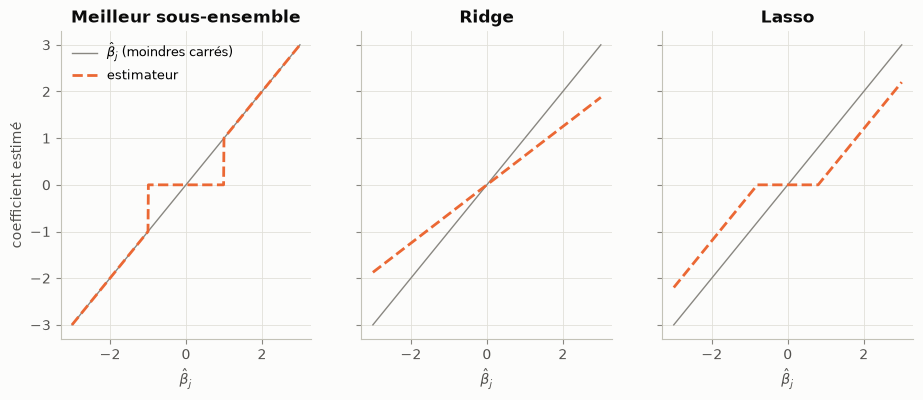

In [5]:
z = np.linspace(-3, 3, 601)
thr = 1.0                     # |beta_(M)| pour le seuillage dur
fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharey=True)
curves = [("Meilleur sous-ensemble", np.where(np.abs(z) >= thr, z, 0.0)),
          ("Ridge", z / (1 + 0.6)),
          ("Lasso", rc.soft_threshold(z, 0.8))]
for ax, (title, f) in zip(axes, curves):
    ax.plot(z, z, color=GRAY, lw=1, label=r"$\hat\beta_j$ (moindres carrés)")
    ax.plot(z, f, color=ORANGE, ls="--", label="estimateur")
    ax.set_title(title)
    ax.set_xlabel(r"$\hat\beta_j$")
axes[0].set_ylabel("coefficient estimé")
axes[0].legend(loc="upper left")
plt.show()

> **À retenir.** Quand $\mathbf X^T\mathbf X=\mathbf I$, le critère se découple coordonnée
> par coordonnée : le meilleur sous-ensemble fait un **seuillage dur**, la ridge une
> **contraction proportionnelle** $1/(1+\lambda)$, et le lasso un **seuillage doux**
> (translation vers $0$ de $\lambda$, avec annulation des petits coefficients).

## Exercice 3.17 : Le tableau 3.3 sur les données *spam*

**Énoncé (reformulé).** Refaire l'analyse du tableau 3.3 (comparaison des moindres
carrés, du meilleur sous-ensemble, de la ridge, du lasso, de la PCR et des PLS, avec
paramètre de complexité choisi par validation croisée) sur les données *spam* du
chapitre 1.

**Rappel de la méthodologie du livre (section 3.3.4).**
1. Séparer les données en un échantillon d'apprentissage et un échantillon test.
2. Pour chaque méthode, estimer l'erreur de prédiction par **validation croisée à 10
   plis** sur l'apprentissage, pour toute une gamme de valeurs du paramètre de complexité.
3. Choisir le modèle par la **règle « un écart-type »** : le modèle le plus simple dont
   l'erreur de validation croisée est à moins d'un écart-type du minimum.
4. Réajuster sur tout l'apprentissage et mesurer l'erreur quadratique moyenne sur le test
   (avec son écart-type estimé).

### Les données

Le jeu *spam* contient $4601$ courriels décrits par $57$ prédicteurs (fréquences de mots
et de caractères, longueurs de suites de majuscules) et une réponse $y\in\{0,1\}$
($1$ = spam). Choix de mise en œuvre, expliqués :

- **Régression linéaire sur une réponse 0/1.** C'est ce que demande l'exercice (le
  tableau 3.3 est un tableau de régression) ; $\hat y>1/2$ fournit alors une règle de
  classement, dont nous donnons aussi le taux d'erreur.
- **Transformation $\log(x+0{,}1)$.** Les fréquences sont très asymétriques (beaucoup de
  zéros, quelques valeurs énormes) ; cette transformation, utilisée par le livre pour ces
  données au chapitre 9, rend les modèles linéaires bien plus pertinents.
- **Découpage aléatoire** (graine fixée) en $3065$ courriels d'apprentissage et $1536$
  de test, comme au chapitre 9.
- Prédicteurs **centrés-réduits** avec les moyennes et écarts-types de l'apprentissage.

In [6]:
spam = datasets.load_spam()
X_all = np.log(spam.drop(columns="spam").to_numpy(float) + 0.1)
y_all = spam["spam"].to_numpy(float)
rng = np.random.RandomState(0)
perm = rng.permutation(len(y_all))
test_idx, train_idx = perm[:1536], perm[1536:]
Xtr, Xte, _, _ = rc.standardize(X_all[train_idx], X_all[test_idx])
ytr, yte = y_all[train_idx], y_all[test_idx]
# noms des 57 variables (documentation du jeu « spambase ») : fréquences de mots,
# fréquences de caractères, puis statistiques sur les suites de majuscules
words = ["make", "address", "all", "3d", "our", "over", "remove", "internet", "order", "mail",
         "receive", "will", "people", "report", "addresses", "free", "business", "email",
         "you", "credit", "your", "font", "000", "money", "hp", "hpl", "george", "650", "lab",
         "labs", "telnet", "857", "data", "415", "85", "technology", "1999", "parts", "pm",
         "direct", "cs", "meeting", "original", "project", "re", "edu", "table", "conference"]
names = words + ["ch;", "ch(", "ch[", "ch!", "ch$", "ch#", "CAPAVE", "CAPMAX", "CAPTOT"]
p_spam = Xtr.shape[1]
print("apprentissage :", Xtr.shape, " test :", Xte.shape, " proportion de spams :", ytr.mean().round(3))

apprentissage : (3065, 57)  test : (1536, 57)  proportion de spams : 0.389


### Les six méthodes et leur paramètre de complexité

| Méthode | Complexité (de la plus simple à la plus complexe) |
|---|---|
| Moindres carrés | - |
| Meilleur sous-ensemble | taille $k=0,\dots,57$ |
| Ridge | degrés de liberté effectifs $\mathrm{df}(\lambda)=\sum_j d_j^2/(d_j^2+\lambda)$ (éq. (3.50)), $0,\dots,57$ |
| Lasso | facteur de contraction $s=\|\hat\beta^{\text{lasso}}\|_1/\|\hat\beta\|_1\in[0,1]$ |
| PCR | nombre de composantes $M=0,\dots,57$ |
| PLS | nombre de directions $M=0,\dots,57$ |

**Meilleur sous-ensemble.** Une recherche exhaustive sur $2^{57}\approx 1{,}4\cdot10^{17}$
sous-ensembles est impossible (même l'algorithme *leaps and bounds* évoqué en
section 3.3.1 ne dépasse guère $p\approx 40$). Nous la remplaçons par la **sélection pas à
pas ascendante** (*forward stepwise*, section 3.3.2), qui en est l'approximation gloutonne
standard ; c'est la seule entorse à l'esprit du tableau 3.3.

La fonction suivante ajuste, sur un échantillon donné, **tout le chemin** de chaque méthode
(une colonne de coefficients par valeur de complexité). Les entrées sont recentrées sur
l'échantillon utilisé, et l'ordonnée à l'origine vaut $\bar y-\bar{\mathbf x}^T\beta$.

In [7]:
S_GRID = np.linspace(0, 1, 21)    # grille du facteur de contraction du lasso


def fit_paths(method, Xa, ya):
    """Coefficients (p, n_complexités) et ordonnées à l'origine d'une méthode."""
    xm, ym = Xa.mean(axis=0), ya.mean()
    Xc, yc = Xa - xm, ya - ym
    p = Xa.shape[1]
    if method == "Moindres carrés":
        B = np.linalg.lstsq(Xc, yc, rcond=None)[0][:, None]
    elif method == "Meilleur sous-ens.":
        B = rc.forward_stepwise(Xc, yc)[1]
    elif method == "Ridge":
        U, d, Vt = np.linalg.svd(Xc, full_matrices=False)
        lams = np.array([rc.ridge_lambda_for_df(d, k) for k in range(p + 1)])
        B = np.zeros((p, p + 1))
        fin = np.isfinite(lams)
        B[:, fin] = Vt.T @ ((d[:, None] / (d[:, None] ** 2 + lams[fin])) * (U.T @ yc)[:, None])
    elif method == "Lasso":
        path = rc.lars(Xc, yc, method="lasso")
        B = rc.interpolate_path(path["coefs"], S_GRID)
    elif method == "PCR":
        B = rc.pcr(Xc, yc)
    elif method == "PLS":
        B = rc.pls(Xc, yc)["betas"]
    return ym - xm @ B, B


METHODS = ["Moindres carrés", "Meilleur sous-ens.", "Ridge", "Lasso", "PCR", "PLS"]
COMPLEXITY = {"Moindres carrés": np.array([p_spam]), "Meilleur sous-ens.": np.arange(p_spam + 1),
              "Ridge": np.arange(p_spam + 1), "Lasso": S_GRID,
              "PCR": np.arange(p_spam + 1), "PLS": np.arange(p_spam + 1)}

### Validation croisée à 10 plis

Les mêmes 10 plis servent à toutes les méthodes. Pour chaque pli $k$, on ajuste sur les 9
autres et on calcule l'erreur quadratique moyenne $e_k$ sur le pli. L'erreur de validation
croisée est $\overline{e}=\frac1{10}\sum_k e_k$ et son écart-type estimé
$\widehat{\mathrm{se}} = \mathrm{sd}(e_1,\dots,e_{10})/\sqrt{10}$.

In [8]:
from threadpoolctl import threadpool_limits

# Nos matrices sont petites : le calcul parallèle de la bibliothèque d'algèbre linéaire
# coûte alors plus qu'il ne rapporte, on se limite à un seul fil d'exécution.
threadpool_limits(1)
folds = rc.kfold_indices(len(ytr), 10, np.random.RandomState(1))
cv = {}
for method in METHODS:
    errs = []
    for f in folds:
        mask = np.ones(len(ytr), bool)
        mask[f] = False
        b0, B = fit_paths(method, Xtr[mask], ytr[mask])
        errs.append(np.mean((ytr[f][:, None] - b0 - Xtr[f] @ B) ** 2, axis=0))
    errs = np.array(errs)
    cv[method] = (errs.mean(axis=0), errs.std(axis=0, ddof=1) / np.sqrt(len(folds)))
print("validation croisée terminée")

validation croisée terminée


Courbes d'erreur de validation croisée (analogue de la figure 3.7), avec les barres
d'un écart-type et, en pointillés violets, le modèle retenu par la règle « un
écart-type ».

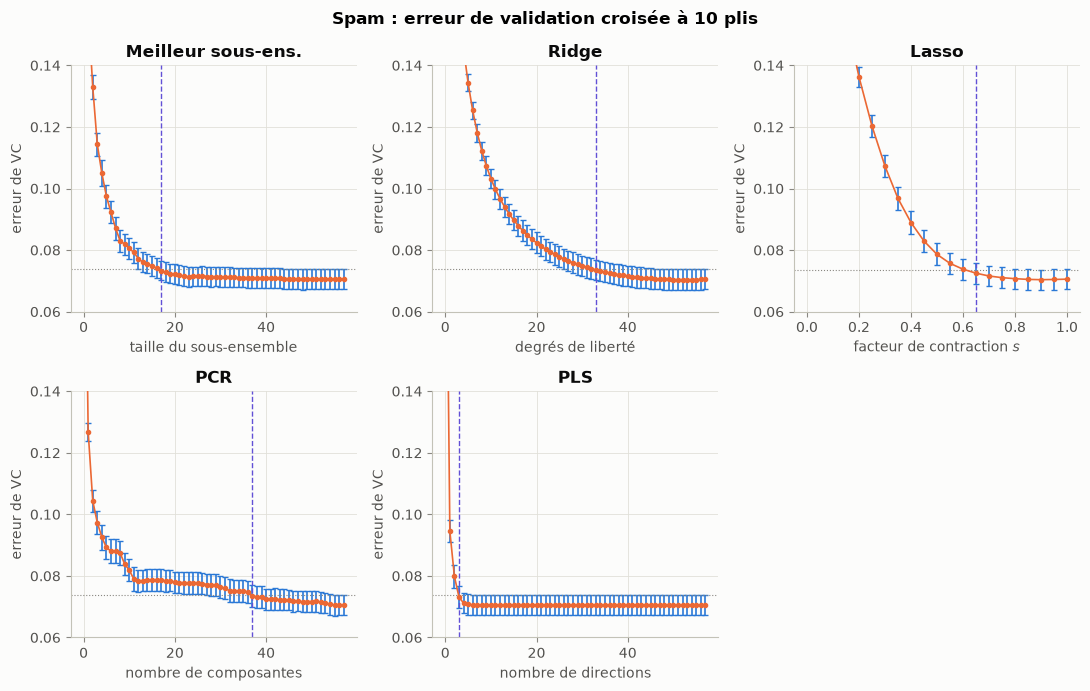

In [9]:
chosen = {"Moindres carrés": 0}
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for ax, method in zip(axes.ravel(), METHODS[1:]):
    mu, se = cv[method]
    cx = COMPLEXITY[method]
    k = rc.one_se_rule(cx, mu, se)
    chosen[method] = k
    ax.errorbar(cx, mu, yerr=se, color=ORANGE, ecolor=BLUE, marker="o", ms=3, lw=1.2, capsize=2)
    ax.axvline(cx[k], color=COLORS[6], ls="--", lw=1)
    ax.axhline(mu.min() + se[np.argmin(mu)], color=GRAY, lw=0.8, ls=":")
    ax.set_title(method)
    ax.set_ylabel("erreur de VC")
    ax.set_ylim(0.06, 0.14)
xlabels = ["taille du sous-ensemble", "degrés de liberté", "facteur de contraction $s$",
           "nombre de composantes", "nombre de directions"]
for ax, lab in zip(axes.ravel(), xlabels):
    ax.set_xlabel(lab)
axes.ravel()[-1].axis("off")
fig.suptitle("Spam : erreur de validation croisée à 10 plis", fontweight="bold")
plt.tight_layout()
plt.show()

### Le tableau final

On réajuste chaque méthode sur tout l'apprentissage avec la complexité retenue, puis on
calcule sur le test l'erreur quadratique moyenne, son écart-type
($\mathrm{sd}$ des erreurs individuelles $/\sqrt{N_{\text{test}}}$) et, en bonus, le taux
de mauvais classement de la règle $\hat y>1/2$.

In [10]:
rows, coefs = {}, {}
for method in METHODS:
    b0, B = fit_paths(method, Xtr, ytr)
    k = chosen[method]
    pred = b0[k] + Xte @ B[:, k]
    sq = (yte - pred) ** 2
    coefs[method] = np.r_[b0[k], B[:, k]]
    rows[method] = {"complexité choisie": "%g" % COMPLEXITY[method][k],
                    "variables non nulles": int(np.sum(np.abs(B[:, k]) > 1e-10)),
                    "erreur test": sq.mean(), "écart-type": sq.std() / np.sqrt(len(sq)),
                    "mauvais classement": np.mean((pred > 0.5) != yte)}
table = pd.DataFrame(rows).T
table.style.format({"erreur test": "{:.4f}", "écart-type": "{:.4f}", "mauvais classement": "{:.4f}"})

,complexité choisie,variables non nulles,erreur test,écart-type,mauvais classement
Moindres carrés,57,57,0.0740,0.0033,0.0684
Meilleur sous-ens.,17,17,0.0785,0.0035,0.0781
Ridge,33,57,0.0770,0.0032,0.0775
Lasso,0.65,33,0.0764,0.0033,0.0742
PCR,37,57,0.0759,0.0034,0.0762
PLS,3,57,0.0759,0.0034,0.0723


Les coefficients complets (57 variables) se lisent mieux en carte de chaleur : couleur
divergente pour le signe, intensité pour la valeur.

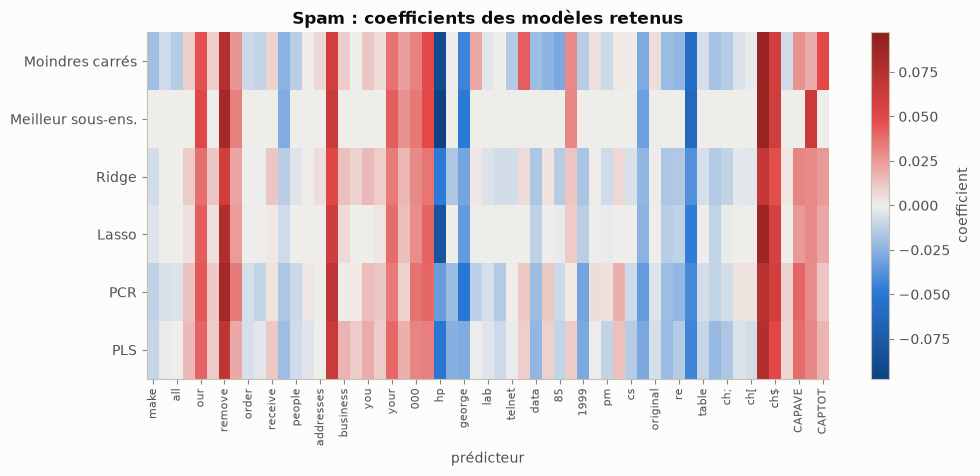

In [11]:
C = pd.DataFrame(coefs, index=["(intercept)"] + names)
vmax = np.abs(C.values[1:]).max()
fig, ax = plt.subplots(figsize=(11, 4.5))
im = ax.imshow(C.values[1:].T, aspect="auto", cmap=DIV, vmin=-vmax, vmax=vmax)
ax.set_yticks(range(len(METHODS)))
ax.set_yticklabels(METHODS)
ax.set_xticks(range(0, p_spam, 2))
ax.set_xticklabels(names[::2], rotation=90, fontsize=8)
ax.set_xlabel("prédicteur")
ax.set_title("Spam : coefficients des modèles retenus")
ax.grid(False)
fig.colorbar(im, ax=ax, label="coefficient")
plt.show()

Les dix variables les plus importantes pour les moindres carrés, et leurs coefficients
dans chaque méthode (les cases nulles correspondent aux variables écartées) :

In [12]:
top = C.iloc[1:].abs()["Moindres carrés"].sort_values(ascending=False).index[:10]
C.loc[["(intercept)"] + list(top)].round(3)

,Moindres carrés,Meilleur sous-ens.,Ridge,Lasso,PCR,PLS
(intercept),0.389,0.389,0.389,0.389,0.389,0.389
ch!,0.089,0.090,0.067,0.088,0.072,0.077
hp,-0.088,-0.097,-0.048,-0.080,-0.033,-0.050
remove,0.076,0.083,0.059,0.077,0.085,0.070
ch$,0.061,0.061,0.047,0.057,0.059,0.050
free,0.059,0.064,0.051,0.060,0.069,0.063
edu,-0.058,-0.061,-0.038,-0.047,-0.041,-0.043
CAPTOT,0.049,0.000,0.025,0.021,0.012,0.017
money,0.048,0.049,0.035,0.040,0.039,0.032
our,0.046,0.050,0.037,0.042,0.044,0.041


### Commentaires

- **Toutes les méthodes font à peu près jeu égal** : les écarts d'erreur test (de l'ordre
  de $0{,}004$) sont comparables aux écarts-types estimés ($\approx0{,}003$). Ici les
  moindres carrés complets sont même légèrement en tête : avec $N=3065\gg p=57$, leur
  variance est faible et la régularisation n'a presque rien à corriger. C'est une
  différence notable avec la prostate ($N=67$), où la contraction aidait.
- Les courbes de validation croisée sont très **plates** près du minimum ; la règle
  « un écart-type » choisit donc des modèles nettement plus simples que le minimum
  (17 variables pour la sélection, 33 pour le lasso, 3 directions PLS), au prix d'une
  petite perte de précision sur le test.
- Les variables les plus influentes sont interprétables : « ! », « $ », « remove »,
  « free », « money » et le nombre total de majuscules poussent vers spam ; « hp », « edu »
  ou « george » (le destinataire d'origine travaillait chez HP et s'appelait George)
  poussent vers non-spam.
- La courbe de validation croisée de **PLS** atteint son plateau dès 3 directions, alors que la
  **PCR** en demande beaucoup plus : PLS construit ses directions en regardant $\mathbf y$.
- Le taux de mauvais classement d'une simple régression linéaire sur la réponse 0/1 est
  déjà correct ; les méthodes de classification des chapitres 4 et 9 font mieux.

> **À retenir.** La procédure du tableau 3.3 (validation croisée à 10 plis + règle
> « un écart-type » + évaluation sur un test indépendant) se transpose telle quelle. Quand
> $N\gg p$, les méthodes de sélection et de contraction ont des performances proches ;
> elles diffèrent surtout par la **parcimonie** et la stabilité des modèles obtenus.

## Exercice 3.18 : Gradient conjugué et moindres carrés partiels

**Énoncé (reformulé).** Se documenter sur les algorithmes de gradient conjugué, et établir
un lien entre ces algorithmes et les moindres carrés partiels (PLS, algorithme 3.3).

Nous allons montrer le résultat suivant (Wold et al., 1984) : **les coefficients PLS
après $m$ étapes sont exactement le $m$-ième itéré du gradient conjugué** appliqué aux
équations normales $\mathbf X^T\mathbf X\beta=\mathbf X^T\mathbf y$ en partant de
$\beta_0=0$.

### Rappel : le gradient conjugué

Soit $\mathbf A$ une matrice $p\times p$ **symétrique définie positive** et
$\mathbf b\in\mathbb R^p$. Résoudre $\mathbf A\beta=\mathbf b$ équivaut à minimiser la
fonction quadratique strictement convexe

$$
\varphi(\beta) = \tfrac12\beta^T\mathbf A\beta - \mathbf b^T\beta,
\qquad \nabla\varphi(\beta) = \mathbf A\beta-\mathbf b .
$$

Le **gradient conjugué** (CG) construit des itérés $\beta_0=0,\beta_1,\beta_2,\dots$ :

1. $\mathbf r_0=\mathbf b$ (résidu $=-\nabla\varphi(\beta_0)$), $\mathbf d_0=\mathbf r_0$ ;
2. pour $k=0,1,\dots$ : $\;\alpha_k=\dfrac{\mathbf r_k^T\mathbf r_k}{\mathbf d_k^T\mathbf A\mathbf d_k}$,
   $\;\beta_{k+1}=\beta_k+\alpha_k\mathbf d_k$, $\;\mathbf r_{k+1}=\mathbf r_k-\alpha_k\mathbf A\mathbf d_k$,
   $\;\mathbf d_{k+1}=\mathbf r_{k+1}+\gamma_k\mathbf d_k$ avec $\gamma_k=\dfrac{\mathbf r_{k+1}^T\mathbf r_{k+1}}{\mathbf r_k^T\mathbf r_k}$.

Le pas $\alpha_k$ minimise exactement $\varphi$ le long de $\mathbf d_k$ ; les directions
sont **$\mathbf A$-conjuguées** ($\mathbf d_i^T\mathbf A\mathbf d_j=0$ si $i\ne j$) et les
résidus sont orthogonaux entre eux ($\mathbf r_i^T\mathbf r_j=0$) et aux directions
précédentes ($\mathbf r_k^T\mathbf d_i=0$ pour $i<k$).

### La propriété fondamentale : optimalité sur les espaces de Krylov

On appelle **espace de Krylov** d'ordre $m$ le sous-espace

$$
\mathcal K_m = \operatorname{Vect}\{\mathbf b,\ \mathbf A\mathbf b,\ \mathbf A^2\mathbf b,\ \dots,\ \mathbf A^{m-1}\mathbf b\}.
$$

**Théorème (admis, classique en analyse numérique).** Tant que $\mathbf r_k\neq0$,
$\operatorname{Vect}\{\mathbf d_0,\dots,\mathbf d_{m-1}\}=\operatorname{Vect}\{\mathbf r_0,\dots,\mathbf r_{m-1}\}=\mathcal K_m$
et

$$
\beta_m = \operatorname*{argmin}_{\beta\in\mathcal K_m}\varphi(\beta).
$$

> **Intuition.** Par récurrence, chaque nouvelle direction est une combinaison de
> $\mathbf r_{k+1}=\mathbf r_k-\alpha_k\mathbf A\mathbf d_k$ et de $\mathbf d_k$ : on gagne
> une puissance de $\mathbf A$ à chaque étape. La conjugaison garantit que le minimum le
> long d'une nouvelle direction ne « défait » pas l'optimisation dans les précédentes :
> $m$ minimisations unidimensionnelles donnent le minimum sur tout $\mathcal K_m$.

### Application aux équations normales

Prenons $\mathbf A=\mathbf X^T\mathbf X$ et $\mathbf b=\mathbf X^T\mathbf y$. En développant
$\|\mathbf y-\mathbf X\beta\|^2 = \mathbf y^T\mathbf y - 2\mathbf y^T\mathbf X\beta+\beta^T\mathbf X^T\mathbf X\beta$, on voit que

$$
\varphi(\beta) = \tfrac12\|\mathbf y-\mathbf X\beta\|^2-\tfrac12\|\mathbf y\|^2 .
$$

Donc le $m$-ième itéré du CG est **l'estimateur des moindres carrés contraint à
l'espace de Krylov** :

$$
\beta^{\text{CG}}_m = \operatorname*{argmin}_{\beta\in\mathcal K_m}\|\mathbf y-\mathbf X\beta\|^2,
\qquad \mathcal K_m = \operatorname{Vect}\{\mathbf X^T\mathbf y,\ (\mathbf X^T\mathbf X)\mathbf X^T\mathbf y,\dots\}.
$$

### Côté PLS : les directions engendrent $\mathbf X\mathcal K_m$

Rappelons l'algorithme 3.3 (entrées centrées-réduites, $\mathbf y$ centré) : à l'étape $m$,
$\mathbf z_m=\mathbf X^{(m-1)}\mathbf X^{(m-1)T}\mathbf y$, puis $\hat{\mathbf y}^{(m)}=\hat{\mathbf y}^{(m-1)}+\hat\theta_m\mathbf z_m$,
puis chaque colonne de $\mathbf X^{(m-1)}$ est orthogonalisée par rapport à $\mathbf z_m$.

**Faits élémentaires.**
- (i) Les $\mathbf z_\ell$ sont deux à deux orthogonaux : $\mathbf z_m$ est combinaison des
  colonnes de $\mathbf X^{(m-1)}$, toutes orthogonales à $\mathbf z_1,\dots,\mathbf z_{m-1}$.
- (ii) Par conséquent $\hat{\mathbf y}^{(m)}=\sum_{\ell\le m}\frac{\langle\mathbf z_\ell,\mathbf y\rangle}{\|\mathbf z_\ell\|^2}\mathbf z_\ell=\mathbf P_m\mathbf y$,
  la **projection orthogonale** de $\mathbf y$ sur $\operatorname{Vect}\{\mathbf z_1,\dots,\mathbf z_m\}$.
- (iii) $\mathbf X^{(m-1)}=(\mathbf I-\mathbf P_{m-1})\mathbf X$ (on a retiré à chaque colonne
  sa projection sur les $\mathbf z$ précédents).

**Proposition.** Pour tout $m$ (tant que $\mathbf z_m\ne0$),
$\operatorname{Vect}\{\mathbf z_1,\dots,\mathbf z_m\} = \mathbf X\mathcal K_m := \{\mathbf X\beta : \beta\in\mathcal K_m\}$.

*Preuve par récurrence.* Pour $m=1$ : $\mathbf z_1 = \mathbf X\mathbf X^T\mathbf y = \mathbf X\mathbf b\in\mathbf X\mathcal K_1$.
Supposons le résultat vrai jusqu'au rang $m-1$. D'après (iii), et comme $\mathbf I-\mathbf P_{m-1}$
est symétrique et idempotente,

$$
\mathbf z_m = (\mathbf I-\mathbf P_{m-1})\mathbf X\,\mathbf X^T(\mathbf I-\mathbf P_{m-1})\mathbf y
= (\mathbf I-\mathbf P_{m-1})\mathbf X\,\mathbf X^T(\mathbf y-\hat{\mathbf y}^{(m-1)}).
$$

Par hypothèse de récurrence, $\hat{\mathbf y}^{(m-1)}\in\mathbf X\mathcal K_{m-1}$, donc
$\hat{\mathbf y}^{(m-1)}=\mathbf X\beta_{m-1}$ avec $\beta_{m-1}\in\mathcal K_{m-1}$. Alors
$\mathbf X^T(\mathbf y-\mathbf X\beta_{m-1}) = \mathbf b-\mathbf A\beta_{m-1}\in\mathcal K_m$
(car $\mathbf A\mathcal K_{m-1}\subset\mathcal K_m$). Ainsi $\mathbf X\mathbf X^T(\mathbf y-\hat{\mathbf y}^{(m-1)})\in\mathbf X\mathcal K_m$,
et $\mathbf P_{m-1}$ lui retire un élément de $\operatorname{Vect}\{\mathbf z_1..\mathbf z_{m-1}\}=\mathbf X\mathcal K_{m-1}\subset\mathbf X\mathcal K_m$.
Donc $\mathbf z_m\in\mathbf X\mathcal K_m$.

On conclut par les dimensions : les $\mathbf z_1,\dots,\mathbf z_m$ sont orthogonaux et non
nuls, donc engendrent un espace de dimension $m$, inclus dans $\mathbf X\mathcal K_m$ qui
est de dimension $\le m$. Les deux espaces sont égaux. $\square$

### Conclusion : PLS $=$ gradient conjugué

D'après (ii), $\hat{\mathbf y}^{(m)}$ est la projection de $\mathbf y$ sur
$\mathbf X\mathcal K_m$, c'est-à-dire $\mathbf X\beta$ où $\beta$ minimise
$\|\mathbf y-\mathbf X\beta\|^2$ sur $\mathcal K_m$. C'est exactement $\mathbf X\beta^{\text{CG}}_m$.
Si $\mathbf X$ est de rang plein, $\beta\mapsto\mathbf X\beta$ est injective et

$$
\boxed{\hat\beta^{\text{pls}}(m) = \beta^{\text{CG}}_m .}
$$

**Conséquences.**
- Le CG termine en au plus $q$ étapes, où $q$ est le nombre de valeurs propres distinctes
  de $\mathbf X^T\mathbf X$ « vues » par $\mathbf b$ : si $\mathbf X$ est orthogonale
  ($\mathbf X^T\mathbf X=c\,\mathbf I$), $\mathcal K_1=\mathcal K_p$ et PLS donne les moindres
  carrés **dès la première étape** - ce qu'affirme le livre en fin de section 3.5.2.
- Arrêter le CG tôt est une forme de **régularisation** : c'est la régularisation de PLS.

### Vérification numérique

Sur des données corrélées, on compare les coefficients PLS (algorithme 3.3) aux itérés du
gradient conjugué.

In [13]:
rng = np.random.RandomState(0)
N, p = 80, 6
cov = 0.7 ** np.abs(np.subtract.outer(np.arange(p), np.arange(p)))
Xc = rng.randn(N, p) @ np.linalg.cholesky(cov).T
yc = Xc @ rng.randn(p) + rng.randn(N)
Xs, _, _, _ = rc.standardize(Xc)
ys = yc - yc.mean()
b_pls = rc.pls(Xs, ys)["betas"]
b_cg = rc.conjugate_gradient(Xs.T @ Xs, Xs.T @ ys)
print("écart max PLS / CG pour m = 0..p :", np.abs(b_pls - b_cg).max(axis=0))

écart max PLS / CG pour m = 0..p : [0. 0. 0. 0. 0. 0. 0.]


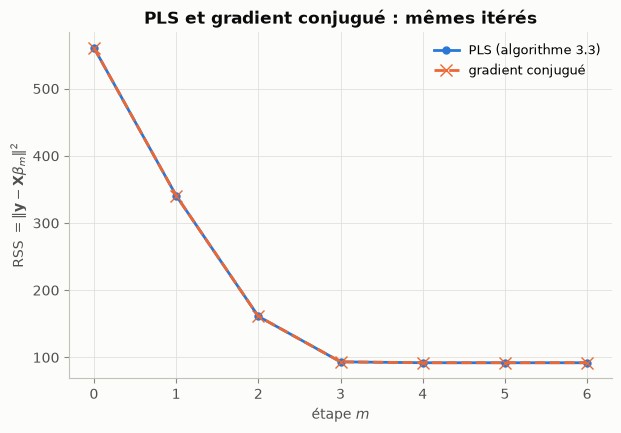

In [14]:
rss_pls = np.sum((ys[:, None] - Xs @ b_pls) ** 2, axis=0)
fig, ax = plt.subplots()
ax.plot(range(p + 1), rss_pls, "o-", color=BLUE, label="PLS (algorithme 3.3)")
ax.plot(range(p + 1), np.sum((ys[:, None] - Xs @ b_cg) ** 2, axis=0), "x--", color=ORANGE,
        ms=9, label="gradient conjugué")
ax.set_xlabel("étape $m$")
ax.set_ylabel(r"RSS $=\|\mathbf{y}-\mathbf{X}\beta_m\|^2$")
ax.set_title("PLS et gradient conjugué : mêmes itérés")
ax.legend()
plt.show()

Cas d'entrées orthogonales : une seule étape suffit.

In [15]:
Xorth = np.linalg.qr(rng.randn(N, p))[0] * np.sqrt(N)
b_orth = rc.pls(Xorth, ys)["betas"]
b_ls_orth = np.linalg.lstsq(Xorth, ys, rcond=None)[0]
print("PLS(1) = moindres carrés :", np.allclose(b_orth[:, 1], b_ls_orth))

PLS(1) = moindres carrés : True


> **À retenir.** Les PLS ne sont rien d'autre que le **gradient conjugué** appliqué aux
> équations normales et arrêté avant convergence : $\hat\beta^{\text{pls}}(m)$ minimise la
> somme des carrés résiduelle sur l'espace de Krylov
> $\operatorname{Vect}\{\mathbf X^T\mathbf y,\dots,(\mathbf X^T\mathbf X)^{m-1}\mathbf X^T\mathbf y\}$.